# GMM Fraud Triage: Audited Baseline

This notebook audits the saved GMM baseline and verifies that its scaler and GMM were trained on **legitimate training transactions only**. It also performs one explicitly labeled comparison with a GMM trained on mixed training labels.

No validation/test labels are used to fit the saved model or scaler. Validation is used only to verify calibration and model selection. The test set is not inspected until model selection is complete.

## 1. Google Colab setup

Place the project at `MyDrive/card-fraud-triage`, or run from the repository root locally.

In [1]:
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/card-fraud-triage")
else:
    PROJECT_ROOT = Path.cwd().resolve()
    if not (PROJECT_ROOT / "src" / "config.py").is_file():
        PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "creditcard_clean.csv"
MODEL_PATH = PROJECT_ROOT / "artifacts" / "gmm_model.joblib"
REPORT_PATH = PROJECT_ROOT / "artifacts" / "gmm_report.json"
for path in (DATA_PATH, MODEL_PATH, REPORT_PATH):
    if not path.is_file():
        raise FileNotFoundError("Required file missing: {}".format(path))

print("Project root:", PROJECT_ROOT)

Project root: /Users/yuvrajchandravansi/Desktop/card-fraud-triage


## 2. Imports and fixed configuration

No preprocessing or model fitting is performed before the chronological split.

In [2]:
import os
import sys

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import hashlib
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             confusion_matrix, precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score)

sys.path.insert(0, str(PROJECT_ROOT))
from src.config import SEED
from src.scoring import validate_model_bundle

np.random.seed(SEED)
%matplotlib inline

## 3. Load and verify chronological partitions

The dataset is sorted only by elapsed `Time`. Boundaries are non-overlapping and are based on fixed 60/20/20 row positions.

In [3]:
data = pd.read_csv(DATA_PATH).sort_values("Time").reset_index(drop=True)
train_end = int(len(data) * 0.60)
validation_end = int(len(data) * 0.80)
train = data.iloc[:train_end].copy()
validation = data.iloc[train_end:validation_end].copy()
test = data.iloc[validation_end:].copy()

split = pd.DataFrame({
    "rows": [len(train), len(validation), len(test)],
    "legitimate": [(train.Class == 0).sum(), (validation.Class == 0).sum(), (test.Class == 0).sum()],
    "frauds": [train.Class.sum(), validation.Class.sum(), test.Class.sum()],
    "time_min": [train.Time.min(), validation.Time.min(), test.Time.min()],
    "time_max": [train.Time.max(), validation.Time.max(), test.Time.max()],
}, index=["train", "validation", "test"])
display(split)

assert train.Time.max() < validation.Time.min()
assert validation.Time.max() < test.Time.min()
assert validation.Time.min() >= train.Time.max()
assert test.Time.min() >= validation.Time.max()
assert data.Time.is_monotonic_increasing

,rows,legitimate,frauds,time_min,time_max
train,170235,169893,342,0.0,120392.0
validation,56745,56688,57,120393.0,145233.0
test,56746,56672,74,145234.0,172792.0


## 4. Load and validate the final saved artifact

The saved scaler and GMM are loaded exactly once. Reproducibility metadata and estimator dimensions are checked before scoring.

In [4]:
bundle = joblib.load(MODEL_PATH)
report = json.loads(REPORT_PATH.read_text())
validate_model_bundle(bundle)
features = bundle["feature_names"]
model = bundle["model"]
scaler = bundle["scaler"]
threshold = float(bundle["threshold"])

clean_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert clean_sha256 == bundle["cleaned_dataset_sha256"]

assert "Class" not in features and "Time" not in features
assert bundle["target_false_positive_rate"] == 0.01
assert bundle["random_seed"] == SEED

print("Configuration:", bundle["feature_configuration"])
print("GMM: {} components / {} covariance".format(bundle["selected_components"], bundle["covariance_type"]))
print("Threshold:", round(threshold, 6))
print("Artifact cleaned-data SHA-256:", clean_sha256[:12], "...")

Configuration: without_time
GMM: 4 components / full covariance
Threshold: 69.038566
Artifact cleaned-data SHA-256: a9fa2e47a9fc ...


## 5. Verify legitimate-only scaler fitting

The saved scaler is compared with a fresh scaler fitted only on legitimate training rows. This confirms that the saved scaling statistics match the required training population.

In [5]:
legitimate_train = train.loc[train["Class"] == 0, features]
reference_scaler = __import__("sklearn.preprocessing", fromlist=["StandardScaler"]).StandardScaler().fit(legitimate_train)

assert bundle["training_legitimate_rows"] == len(legitimate_train)
assert scaler.n_features_in_ == len(features)
np.testing.assert_allclose(scaler.mean_, reference_scaler.mean_, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(scaler.var_, reference_scaler.var_, rtol=1e-12, atol=1e-12)
np.testing.assert_array_equal(scaler.feature_names_in_, np.asarray(features))

print("Legitimate training rows used:", len(legitimate_train))
print("Excluded training fraud rows:", int(train["Class"].sum()))
print("Scaler statistics match legitimate-only reference: yes")

Legitimate training rows used: 169893
Excluded training fraud rows: 342
Scaler statistics match legitimate-only reference: yes


## 6. Verify validation-only threshold calibration

The threshold is recomputed from legitimate validation scores. It must equal the threshold stored in the saved artifact.

In [6]:
validation_scores = -model.score_samples(scaler.transform(validation.loc[:, features]))
legitimate_validation_scores = validation_scores[validation["Class"] == 0]
recomputed_threshold = float(np.quantile(legitimate_validation_scores, 1 - bundle["target_false_positive_rate"]))
validation_alert = validation_scores >= recomputed_threshold
validation_false_positive_rate = np.mean(validation_alert[validation["Class"] == 0])

np.testing.assert_allclose(threshold, recomputed_threshold, rtol=0, atol=1e-10)
assert abs(validation_false_positive_rate - bundle["target_false_positive_rate"]) < 0.0001

print("Target validation FPR: {:.2%}".format(bundle["target_false_positive_rate"]))
print("Observed validation FPR: {:.2%}".format(validation_false_positive_rate))
print("Saved/recomputed threshold:", round(threshold, 6))

Target validation FPR: 1.00%
Observed validation FPR: 1.00%
Saved/recomputed threshold: 69.038566


## 7. Validation performance and false-positive trade-offs

The saved artifact’s validation metrics are compared with recomputed scores. These metrics are independent of the test set.

In [7]:
y_validation = validation["Class"].to_numpy(dtype=int)
validation_ap = average_precision_score(y_validation, validation_scores)
validation_recall = ((validation_scores >= threshold) & (y_validation == 1)).sum() / y_validation.sum()
validation_precision = ((validation_scores >= threshold) & (y_validation == 1)).sum() / (validation_scores >= threshold).sum()

threshold_rows = []
for candidate in report["threshold"]["validation_threshold_comparison"]:
    m = candidate["validation_metrics"]
    threshold_rows.append({
        "target FPR": candidate["target_fpr"],
        "threshold": round(candidate["threshold"], 6),
        "observed FPR": m["false_positive_rate"],
        "precision": m["precision"],
        "recall": m["recall_tpr"],
    })
threshold_table = pd.DataFrame(threshold_rows).set_index("target FPR")
display(threshold_table)

assert abs(validation_ap - report["validation_metrics"]["average_precision"]) < 1e-12
print("Saved validation AP:", round(report["validation_metrics"]["average_precision"], 6))
print("Recomputed validation AP:", round(validation_ap, 6))
print("Validation recall at 1% FPR:", "{:.2%}".format(validation_recall))
print("Validation precision at 1% FPR:", "{:.2%}".format(validation_precision))

,threshold,observed FPR,precision,recall
target FPR,,,,
0.005,87.261801,0.005010,0.134146,0.771930
0.010,69.038566,0.010002,0.072013,0.771930
0.020,58.173533,0.020004,0.038168,0.789474


Saved validation AP: 0.710811
Recomputed validation AP: 0.710811
Validation recall at 1% FPR: 77.19%
Validation precision at 1% FPR: 7.20%


## 8. Plot the validation precision-recall curve

The held-out test set remains unused in this section.

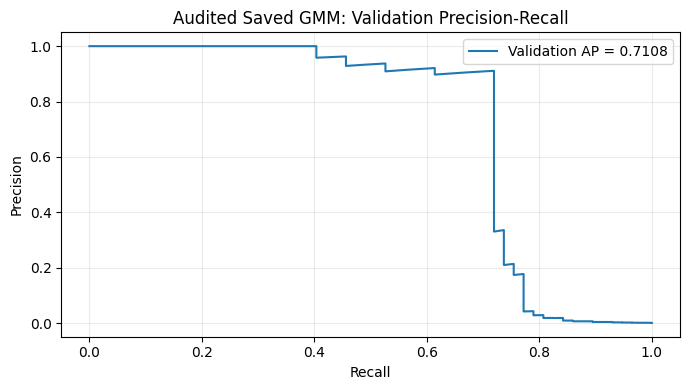

In [8]:
precision, recall, _ = precision_recall_curve(y_validation, validation_scores)
plt.figure(figsize=(7, 4))
plt.plot(recall, precision, label="Validation AP = {:.4f}".format(validation_ap))
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Audited Saved GMM: Validation Precision-Recall")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 9. Comparison-only mixed-training experiment

This GMM is **not** the final model. It is trained on all 170,235 training rows, including fraud labels, solely to document whether mixed-label fitting improves validation behavior. The saved legitimate-only model is already the final candidate and is selected here without using test metrics.

In [9]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

comparison_scaler = StandardScaler().fit(train.loc[:, features])
comparison_gmm = GaussianMixture(
    n_components=2,
    covariance_type="full",
    n_init=1,
    max_iter=150,
    reg_covar=1e-6,
    random_state=SEED,
).fit(comparison_scaler.transform(train.loc[:, features]))
comparison_scores = -comparison_gmm.score_samples(comparison_scaler.transform(validation.loc[:, features]))
comparison_ap = average_precision_score(y_validation, comparison_scores)

comparison_summary = pd.DataFrame({
    "training population": ["legitimate-only", "all training rows"],
    "validation AP": [validation_ap, comparison_ap],
    "selected as final": ["yes", "no"],
}, index=["saved model", "mixed-label comparison"])
display(comparison_summary)

assert validation_ap > comparison_ap
print("Final model remains the saved legitimate-only GMM.")

,training population,validation AP,selected as final
saved model,legitimate-only,0.710811,yes
mixed-label comparison,all training rows,0.170549,no


Final model remains the saved legitimate-only GMM.


## 10. Evaluate the final model on the untouched test set

This is the one and only test evaluation. Test labels were not used to fit, select, or calibrate the saved model.

In [10]:
test_scores = -model.score_samples(scaler.transform(test.loc[:, features]))
y_test = test["Class"].to_numpy(dtype=int)
test_alert = test_scores >= threshold
tn, fp, fn, tp = confusion_matrix(y_test, test_alert, labels=[0, 1]).ravel()
precision, recall, f1, _ = precision_recall_fscore_support(y_test, test_alert, average="binary", zero_division=0)
test_metrics = pd.Series({
    "average precision": average_precision_score(y_test, test_scores),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "precision": precision,
    "recall": recall,
    "F1": f1,
    "false-positive rate": fp / (fp + tn),
})
display(test_metrics.to_frame("test").round(6))

assert abs(test_metrics["average precision"] - report["test_metrics"]["average_precision"]) < 1e-12
assert int(tp) == report["test_metrics"]["frauds_detected"]
assert int(fn) == report["test_metrics"]["frauds_missed"]

,test
average precision,0.591341
ROC-AUC,0.935295
precision,0.149871
recall,0.783784
F1,0.251627
false-positive rate,0.005805


## 11. Test confusion matrix and review capacity

The matrix shows the operational effect of the validated threshold. Review capacities show a trade-off between analyst volume and recall.

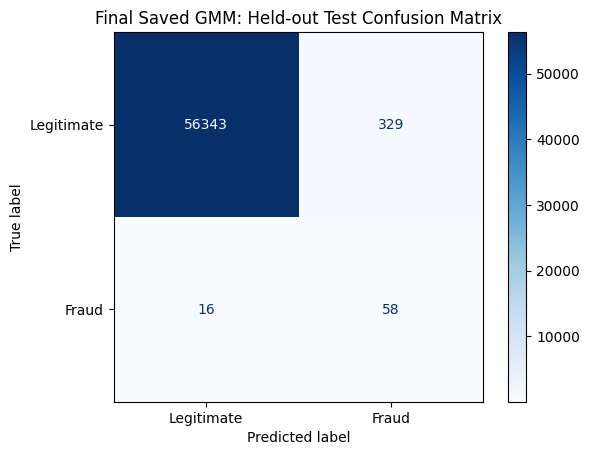

,frauds detected,precision@K,recall@K
review capacity,,,
100,56,0.560,0.756757
500,58,0.116,0.783784
1000,60,0.060,0.810811


Frauds detected: 58 of 74
Frauds missed: 16
Legitimate false alerts: 329


In [11]:
ConfusionMatrixDisplay(confusion_matrix(y_test, test_alert), display_labels=["Legitimate", "Fraud"]).plot(cmap="Blues", values_format="d")
plt.title("Final Saved GMM: Held-out Test Confusion Matrix")
plt.grid(False)
plt.show()

capacity_rows = []
ranked = np.argsort(-test_scores)
for row in report["capacity_metrics"]["test"].values():
    capacity_rows.append({
        "review capacity": row["capacity"],
        "frauds detected": row["frauds_detected"],
        "precision@K": row["precision"],
        "recall@K": row["recall"],
    })
display(pd.DataFrame(capacity_rows).set_index("review capacity"))

print("Frauds detected:", int(tp), "of", int(tp + fn))
print("Frauds missed:", int(fn))
print("Legitimate false alerts:", int(fp))

## 12. Limitations and conclusion

The saved final GMM and scaler are consistent with legitimate-only training. Validation Average Precision is `0.710811`; the mixed-training comparison is lower and is not retained.

The test false-positive rate is lower than the 1% validation target, demonstrating threshold drift between chronological periods rather than guaranteed future behavior. The model can miss fraud and still generate many false alerts.

This evidence supports an experimental fraud-triage baseline. It does not establish production readiness, business-approved cost thresholds, or reliability under later data drift.